# Лабораторная работа 2

## Полносвязная нейронная сеть

Реализовать нейронную сеть, состоящую из двух полносвязных слоев и решающую задачу классификации на наборе данных из лабораторной работы 1.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scripts.classifiers.neural_net import TwoLayerNet

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) 
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'


def rel_error(x, y):
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

1. Добавьте реализации методов класса TwoLayerNet . Проверьте вашу реализацию на модельных данных (Код приведен ниже).  

In [2]:
input_size = 4
hidden_size = 10
num_classes = 3
num_inputs = 5

def init_toy_model():
    np.random.seed(0)
    return TwoLayerNet(input_size, hidden_size, num_classes, std=1e-1)

def init_toy_data():
    np.random.seed(1)
    X = 10 * np.random.randn(num_inputs, input_size)
    y = np.array([0, 1, 2, 2, 1])
    return X, y

net = init_toy_model()
X, y = init_toy_data()

# Прямой проход: вычисление выхода сети

Реализуйте первую часть  метода TwoLayerNet.loss, вычисляющую оценки классов для входных данных. 

Сравните ваш выход сети с эталонными значениями. Ошибка должна быть очень маленькой (можете ориентироваться на значение < 1e-7) .

In [3]:
scores = net.loss(X)
print('Your scores:')
print(scores)
print()
print('correct scores:')
correct_scores = np.asarray([
  [-0.81233741, -1.27654624, -0.70335995],
  [-0.17129677, -1.18803311, -0.47310444],
  [-0.51590475, -1.01354314, -0.8504215 ],
  [-0.15419291, -0.48629638, -0.52901952],
  [-0.00618733, -0.12435261, -0.15226949]])
print(correct_scores)
print()


print('Difference between your scores and correct scores:')
print(np.sum(np.abs(scores - correct_scores)))

Your scores:
[[-0.81233741 -1.27654624 -0.70335995]
 [-0.17129677 -1.18803311 -0.47310444]
 [-0.51590475 -1.01354314 -0.8504215 ]
 [-0.15419291 -0.48629638 -0.52901952]
 [-0.00618733 -0.12435261 -0.15226949]]

correct scores:
[[-0.81233741 -1.27654624 -0.70335995]
 [-0.17129677 -1.18803311 -0.47310444]
 [-0.51590475 -1.01354314 -0.8504215 ]
 [-0.15419291 -0.48629638 -0.52901952]
 [-0.00618733 -0.12435261 -0.15226949]]

Difference between your scores and correct scores:
3.6802720745909845e-08



# Прямой проход: вычисление loss

Реализуйте вторую часть метода, вычисляющую значение функции потерь. Сравните с эталоном. Ошибка должна быть очень маленькой (можете ориентироваться на значение < 1e-12) .

In [4]:
loss, _ = net.loss(X, y, reg=0.05)
correct_loss = 1.30378789133

print('Difference between your loss and correct loss:')
print(np.sum(np.abs(loss - correct_loss)))

Difference between your loss and correct loss:
1.794120407794253e-13


# Обратный проход

Реализуйте третью часть метода loss. Используйте численную реализацию расчета градиента для проверки вашей реализации обратного прохода.  Если прямой и обратный проходы реализованы верно, то ошибка будет < 1e-8 для каждой из переменных W1, W2, b1, и b2. 


In [5]:
from scripts.gradient_check import eval_numerical_gradient

loss, grads = net.loss(X, y, reg=0.05)

for param_name in grads:
    f = lambda W: net.loss(X, y, reg=0.05)[0]
    param_grad_num = eval_numerical_gradient(f, net.params[param_name], verbose=False)
    print('%s max relative error: %e' % (param_name, rel_error(param_grad_num, grads[param_name])))

W2 max relative error: 3.440708e-09
b2 max relative error: 4.447646e-11
W1 max relative error: 3.561318e-09
b1 max relative error: 2.738422e-09


# Обучение нейронной сети на смоделированных данных

Реализуйте методы TwoLayerNet.train и TwoLayerNet.predict. Обучайте сеть до тех пор, пока значение loss не будет < 0.02.


Final training loss:  0.017149607938732093


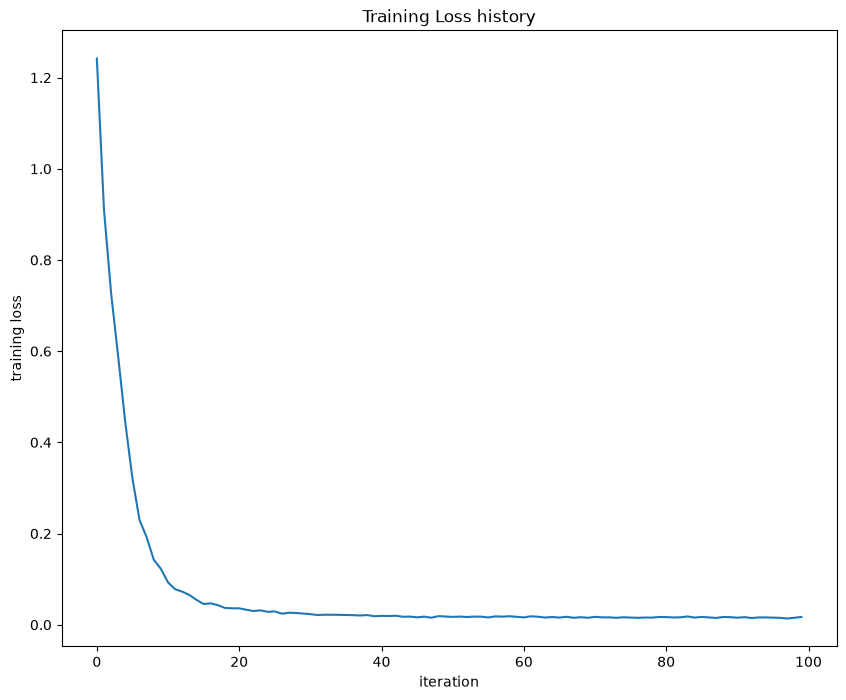

In [6]:
net = init_toy_model()
stats = net.train(X, y, X, y,
            learning_rate=1e-1, reg=5e-6,
            num_iters=100, verbose=False)

toy_loss = stats['loss_history'][-1]
print('Final training loss: ', toy_loss)
assert toy_loss < 0.02


plt.plot(stats['loss_history'])
plt.xlabel('iteration')
plt.ylabel('training loss')
plt.title('Training Loss history')
plt.show()

# Обучение нейронной сети на реальном наборе данных (CIFAR-10, MNIST)

Загрузите набор данных, соответствующий вашему варианту. 

Разделите данные на обучающую, тестовую и валидационную выборки.

Выполните предобработку данных, как в ЛР 1. 

Обучите нейронную сеть на ваших данных. 

При сдаче лабораторной работы объясните значения всех параметров метода train.

In [7]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
X = digits.data.astype(np.float32)
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

X_train /= 16.0
X_val /= 16.0
X_test /= 16.0

mean_image = np.mean(X_train, axis=0)
X_train -= mean_image
X_val -= mean_image
X_test -= mean_image

print('Train:', X_train.shape, y_train.shape)
print('Validation:', X_val.shape, y_val.shape)
print('Test:', X_test.shape, y_test.shape)
np.random.seed(42)


Train: (1077, 64) (1077,)
Validation: (270, 64) (270,)
Test: (450, 64) (450,)


In [8]:
input_size = 8 * 8
hidden_size = 50
num_classes = 10
net = TwoLayerNet(input_size, hidden_size, num_classes)

stats = net.train(X_train, y_train, X_val, y_val,
            num_iters=1000, batch_size=200,
            learning_rate=1e-4, learning_rate_decay=0.95,
            reg=0.25, verbose=True)

val_acc = (net.predict(X_val) == y_val).mean()
print('Validation accuracy: ', val_acc)

iteration 0 / 1000: loss 2.302594
iteration 100 / 1000: loss 2.302594
iteration 200 / 1000: loss 2.302594
iteration 300 / 1000: loss 2.302595
iteration 400 / 1000: loss 2.302595
iteration 500 / 1000: loss 2.302595
iteration 600 / 1000: loss 2.302596
iteration 700 / 1000: loss 2.302592
iteration 800 / 1000: loss 2.302593
iteration 900 / 1000: loss 2.302596
Validation accuracy:  0.1037037037037037


Используя параметры по умолчанию, вы можете получить accuracy, примерно равный 0.29. 

Проведите настройку гиперпараметров для увеличения accuracy. Поэкспериментируйте со значениями гиперпараметров, например, с количеством скрытых слоев, количеством эпох, скорости обучения и др. Ваша цель - максимально увеличить accuracy полносвязной сети на валидационном наборе. Различные эксперименты приветствуются. Например, вы можете использовать методы для сокращения размерности признакового пространства (например, PCA), добавить dropout слои и др. 

Для лучшей модели вычислите acсuracy на тестовом наборе. 

Для отладки процесса обучения часто помогают графики изменения loss и accuracy в процессе обучения. Ниже приведен код построения таких графиков. 

In [9]:
baseline_val_acc = val_acc
best_val_acc = -1
best_net = None
best_stats = None
best_params = None
results = {}

for hidden_size, learning_rate, reg in [(32, 0.1, 1e-4),
                                      (64, 0.1, 1e-4),
                                      (64, 0.05, 5e-4)]:
    np.random.seed(42)
    model = TwoLayerNet(input_size, hidden_size, num_classes,
                        std=np.sqrt(2.0 / input_size))
    model_stats = model.train(X_train, y_train, X_val, y_val,
        num_iters=2000, batch_size=64, learning_rate=learning_rate,
        learning_rate_decay=0.99, reg=reg, verbose=False)
    accuracy = np.mean(model.predict(X_val) == y_val)
    params = (hidden_size, learning_rate, reg)
    results[params] = accuracy
    print('hidden_size=%d, learning_rate=%g, reg=%g: val accuracy=%f' %
          (hidden_size, learning_rate, reg, accuracy))
    if accuracy > best_val_acc:
        best_val_acc = accuracy
        best_net, best_stats, best_params = model, model_stats, params

net, stats = best_net, best_stats
test_acc = np.mean(net.predict(X_test) == y_test)
print('Best parameters:', best_params)
print('Best validation accuracy:', best_val_acc)
print('Test accuracy:', test_acc)


hidden_size=32, learning_rate=0.1, reg=0.0001: val accuracy=0.974074
hidden_size=64, learning_rate=0.1, reg=0.0001: val accuracy=0.977778
hidden_size=64, learning_rate=0.05, reg=0.0005: val accuracy=0.970370
Best parameters: (64, 0.1, 0.0001)
Best validation accuracy: 0.9777777777777777
Test accuracy: 0.9688888888888889


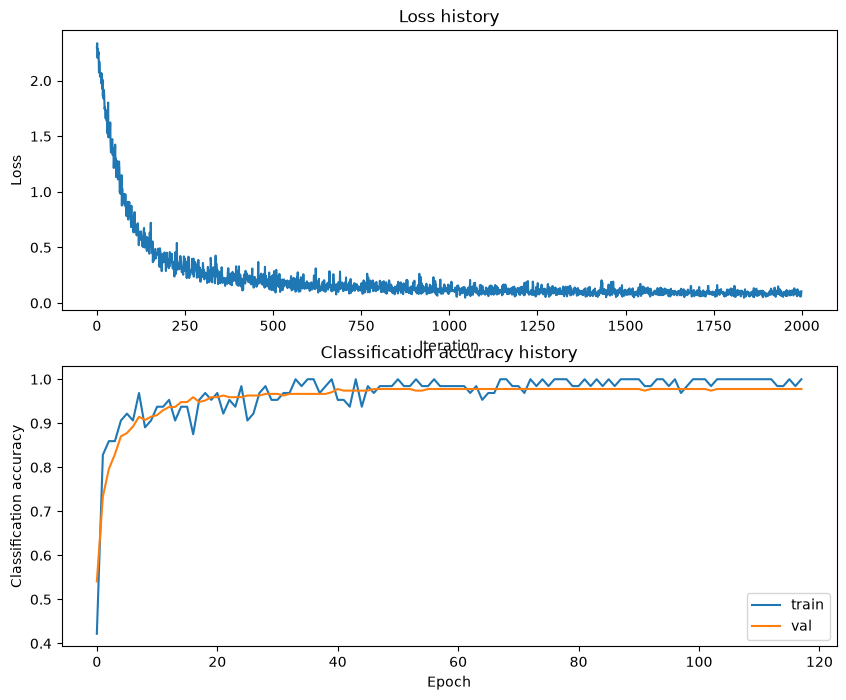

In [10]:
plt.subplot(2, 1, 1)
plt.plot(stats['loss_history'])
plt.title('Loss history')
plt.xlabel('Iteration')
plt.ylabel('Loss')

plt.subplot(2, 1, 2)
plt.plot(stats['train_acc_history'], label='train')
plt.plot(stats['val_acc_history'], label='val')
plt.title('Classification accuracy history')
plt.xlabel('Epoch')
plt.ylabel('Classification accuracy')
plt.legend()
plt.show()

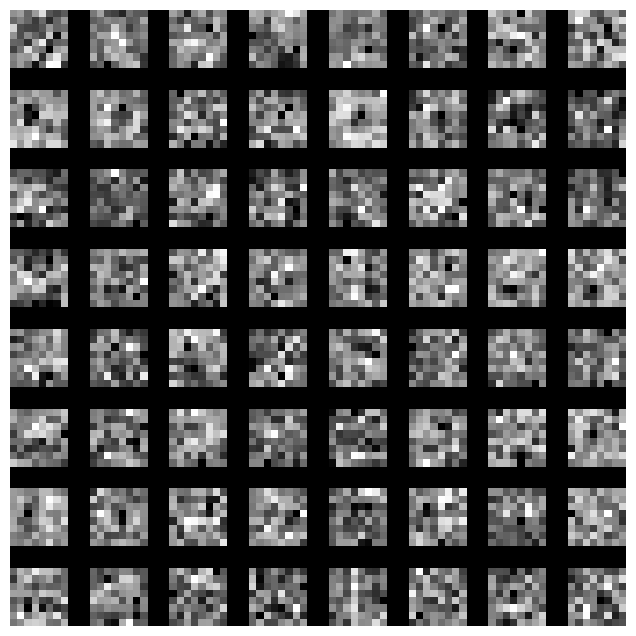

In [11]:
from scripts.vis_utils import visualize_grid

def show_net_weights(net):
    W1 = net.params['W1']
    W1 = W1.reshape(8, 8, 1, -1).transpose(3, 0, 1, 2)
    plt.imshow(visualize_grid(W1, padding=3).astype('uint8')[:, :, 0])
    plt.gca().axis('off')
    plt.show()

show_net_weights(net)

Сделайте выводы по результатам работы. 

In [12]:
print('Выводы:')
print('Реализована двухслойная полносвязная сеть с ReLU и Softmax.')
print('Результаты прямого прохода совпали с эталоном; градиенты проверены численно.')
print('Loss на модельных данных:', toy_loss)
print('Validation accuracy исходной модели: %.4f' % baseline_val_acc)
print('Лучшие гиперпараметры:', best_params)
print('Validation accuracy лучшей модели: %.4f' % best_val_acc)
print('Test accuracy лучшей модели: %.4f' % test_acc)
print('Параметры выбирались по validation, тест использован для итоговой оценки.')


Выводы:
Реализована двухслойная полносвязная сеть с ReLU и Softmax.
Результаты прямого прохода совпали с эталоном; градиенты проверены численно.
Loss на модельных данных: 0.017149607938732093
Validation accuracy исходной модели: 0.1037
Лучшие гиперпараметры: (64, 0.1, 0.0001)
Validation accuracy лучшей модели: 0.9778
Test accuracy лучшей модели: 0.9689
Параметры выбирались по validation, тест использован для итоговой оценки.
